# Formative Assessment 3: Probability, Bayesian Inference, and Gradient Descent

**Group:** 7  
**Group Members:**
1. Jonathan Ishimwe
2. Angel Ingabire
3. Jules Ineza

---

## Table of Contents

1. [**Part 1:** Probability Distributions and the Expectation-Maximization (EM) Algorithm](#part-1)
2. [**Part 2:** Bayesian Probability for Sentiment Analysis](#part-2)
3. [**Part 3:** Manual Calculation of Gradient Descent](#part-3)
4. [**Part 4:** Gradient Descent Implementation Using Python and SciPy](#part-4)

---

* **Tools and Libraries:** `Python`, `NumPy`, `SciPy`, and `Matplotlib`

In [29]:
import csv
import io
import math
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.differentiate import derivative

# Configure global plotting aesthetics
sns.set_theme(style="whitegrid", context="notebook")
%matplotlib inline

<a id='part-1'></a>
# Part 1: Probability Distributions & Expectation-Maximization (EM)
### Case Study: Mothers vs. Children Heights

#### Objectives & Steps
1. **Data Prep:** Inspect the GaltonFamilies dataset and extract one height per mother (family-level) and one height per child.
2. **Unsupervised Learning:** Fit a two-component Gaussian mixture using the EM algorithm without using group labels.
3. **Tracking Updates:** Show the parameter initialization and the first two updates in a tracking table.
4. **Visualization:** Plot both the log-likelihood convergence and the final fitted mixture density.
5. **Posterior Evaluation:** Calculate the posterior probabilities for a test height.
6. **Analysis:** Explain why splitting at the global mean is not a reliable substitute for the EM algorithm.

> **Note on Conventions:** The component names *Children* (higher-mean) and *Mothers* (lower-mean) are used purely as a reporting convention. The EM algorithm models statistical components and does not guarantee that every observation grouped into a component belongs to that true demographic category.

In [30]:
sns.set_theme(style="whitegrid", context="notebook")

### 1. Load and Inspect the Dataset

Each row in the GaltonFamilies dataset records a single child. Consequently, a mother's height is repeated for families with multiple children. To prevent sampling bias, we construct the **Mothers** sample by taking exactly one unique record per family. The **Children** sample will retain all children observations.

In [31]:
data = pd.read_csv("GaltonFamilies.csv")

print("Dataset shape:", data.shape)
display(data.head())

print("\nColumn data types:")
print(data.dtypes)

print("\nSummary statistics:")
display(data[["father", "mother", "childHeight"]].describe().round(2))

print("Unique families:", data["family"].nunique())
print("Child observations:", len(data))
print("Missing values:", int(data.isna().sum().sum()))

Dataset shape: (934, 9)


,rownames,family,father,mother,midparentHeight,children,childNum,gender,childHeight
0,1,001,78.5,67.0,75.43,4,1,male,73.2
1,2,001,78.5,67.0,75.43,4,2,female,69.2
2,3,001,78.5,67.0,75.43,4,3,female,69.0
3,4,001,78.5,67.0,75.43,4,4,female,69.0
4,5,002,75.5,66.5,73.66,4,1,male,73.5



Column data types:
rownames             int64
family              object
father             float64
mother             float64
midparentHeight    float64
children             int64
childNum             int64
gender              object
childHeight        float64
dtype: object

Summary statistics:


,father,mother,childHeight
count,934.00,934.00,934.00
mean,69.20,64.09,66.75
std,2.48,2.29,3.58
min,62.00,58.00,56.00
25%,68.00,63.00,64.00
50%,69.00,64.00,66.50
75%,71.00,65.88,69.70
max,78.50,70.50,79.00


Unique families: 205
Child observations: 934
Missing values: 0


### 2. Prepare the Two Height Samples

* **Mothers:** One unique height observation per family group.
* **Children:** One height observation per child.

We will overlay histograms to descriptively contrast these samples. Note that these demographic labels are only used for descriptive visualization; the EM algorithm will operate blindly on the pooled, unlabeled heights.

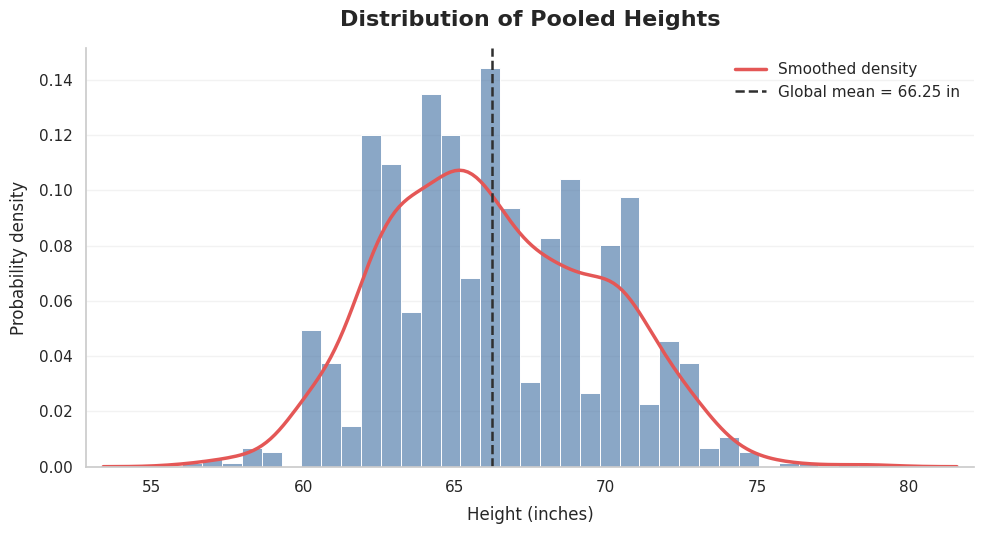

In [32]:
mothers = data.groupby("family")["mother"].first().to_numpy()
children = data["childHeight"].to_numpy()

rng = np.random.default_rng(42)

x = np.concatenate([mothers, children])
x = x[rng.permutation(len(x))]

sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(10, 5.5))

sns.histplot(x=x, bins=35, stat="density", color="#4C78A8", alpha=0.65, edgecolor="white", linewidth=0.7, ax=ax)

sns.kdeplot(x=x, color="#E45756", linewidth=2.5, ax=ax, label="Smoothed density")

global_mean = x.mean()

ax.axvline(global_mean, color="#2F2F2F", linestyle="--", linewidth=1.8, label=f"Global mean = {global_mean:.2f} in")

ax.set_title("Distribution of Pooled Heights", fontsize=16, fontweight="bold", pad=16)
ax.set_xlabel("Height (inches)", fontsize=12, labelpad=8)
ax.set_ylabel("Probability density", fontsize=12, labelpad=8)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", alpha=0.25)
ax.grid(axis="x", visible=False)

ax.legend(frameon=False, loc="upper right")
ax.margins(x=0.02)

plt.tight_layout()
plt.show()

> **Observation:** The prepared subset contains **205 mothers** and **934 children**. While their respective sample means differ significantly, the distributions heavily overlap. This overlap demonstrates why individual heights cannot be classified into groups with absolute certainty based on value alone.

### 3. Create the Unlabeled Pooled Dataset

We combine the heights into a single 1D array $x$ and shuffle the elements. Shuffling ensures that the order of data collection does not bias the initialization or parameter updates. No classification labels are passed to the EM algorithm.

Number of pooled heights: 1139
Global mean: 66.252 inches
Global variance: 12.580 square inches
Global standard deviation: 3.547 inches


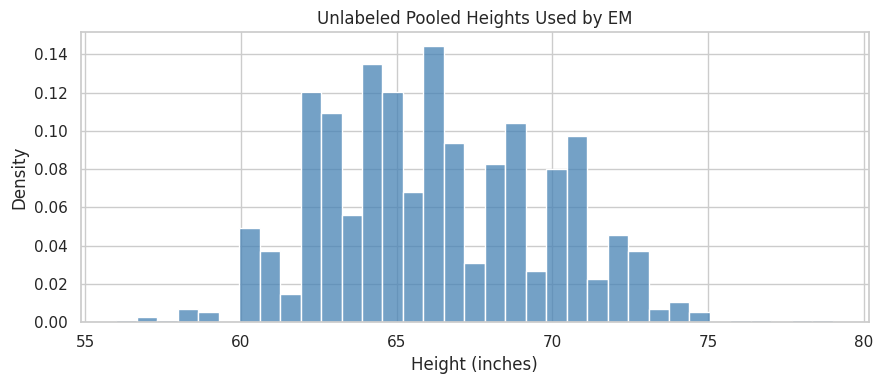

In [33]:
rng = np.random.default_rng(42)

x = np.concatenate([mothers, children])
x = x[rng.permutation(len(x))]
n = len(x)

print(f"Number of pooled heights: {n}")
print(f"Global mean: {x.mean():.3f} inches")
print(f"Global variance: {x.var():.3f} square inches")
print(f"Global standard deviation: {x.std():.3f} inches")

# The model uses only pooled heights; no group labels are supplied to EM.
plt.figure(figsize=(9, 4))
sns.histplot(x=x, bins=35, stat="density", color="steelblue")
plt.xlabel("Height (inches)")
plt.ylabel("Density")
plt.title("Unlabeled Pooled Heights Used by EM")
plt.tight_layout()
plt.show()

#### Summary of Unlabeled Pooled Data
- **Number of pooled heights ($n$):** 1,139
- **Global mean:** 66.252 inches
- **Global variance:** 12.580 $\text{in}^2$
- **Global standard deviation:** 3.547 inches

### 4. Mathematical Setup for the Two-Component Gaussian Mixture

For each observation $x_i$, the model assumes a mixture of two normal components:

$$p(x_i) = \sum_{k=1}^{2} \pi_k \mathcal{N}(x_i \mid \mu_k, \sigma_k^2)$$

Where the probability density function (PDF) for each component is defined as:

$$\mathcal{N}(x_i \mid \mu_k, \sigma_k^2) = \frac{1}{\sqrt{2\pi \sigma_k^2}} \exp\left( -\frac{(x_i - \mu_k)^2}{2\sigma_k^2} \right)$$

Here, $\mu_k$ represents the component mean, $\sigma_k^2$ is the variance, and $\pi_k$ is the mixing weight. The mixing weights must satisfy:

$$\sum_{k=1}^{2} \pi_k = 1, \quad \pi_k \ge 0$$

* **Reporting convention:** Component 1 (higher mean) is labeled **Children**, and Component 2 (lower mean) is labeled **Mothers**.

In [34]:
def gaussian_pdf(x, mu, var):
    var = np.maximum(var, 1e-12)
    return np.exp(-((x - mu) ** 2) / (2 * var)) / np.sqrt(2 * np.pi * var)

#### Parameter Initialization

We initialize the parameters using the quantiles of the pooled data to separate the initial component means, while sharing the global variance:

* **Means:** $\mu_1^{(0)} = P_{75}(x)$, $\mu_2^{(0)} = P_{25}(x)$
* **Variances:** $\sigma_1^{2(0)} = \sigma_2^{2(0)} = \text{Var}(x)$
* **Weights:** $\pi_1^{(0)} = \pi_2^{(0)} = 0.5$

This setup provides a stable starting state prior to the first E-step update.

In [35]:
def initialize(x):
    mu = np.array([np.percentile(x, 75), np.percentile(x, 25)], dtype=float)
    global_variance = np.var(x)
    var = np.array([global_variance, global_variance], dtype=float)
    pi = np.array([0.5, 0.5], dtype=float)
    return mu, var, pi

mu0, var0, pi0 = initialize(x)

print("Initial means:", mu0)
print("Initial variances:", var0)
print("Initial weights:", pi0)
print("Weights sum to 1:", np.isclose(pi0.sum(), 1.0))

Initial means: [69.  63.5]
Initial variances: [12.58016036 12.58016036]
Initial weights: [0.5 0.5]
Weights sum to 1: True


#### 5.1 Weighted Densities and Log-Likelihood

We define the log-likelihood function to monitor convergence:

$$\ln L(\theta \mid x) = \sum_{i=1}^{n} \ln \left( \sum_{k=1}^{2} \pi_k \mathcal{N}(x_i \mid \mu_k, \sigma_k^2) \right)$$

In [36]:
def weighted_pdfs(x, mu, var, pi):
    """Return pi_k * N(x_i | mu_k, var_k) for each observation and component."""
    return np.column_stack([
        pi[k] * gaussian_pdf(x, mu[k], var[k])
        for k in range(2)
    ])

def log_likelihood(x, mu, var, pi):
    total_density = weighted_pdfs(x, mu, var, pi).sum(axis=1)
    total_density = np.maximum(total_density, np.finfo(float).tiny)
    return np.sum(np.log(total_density))

print(f"Initial log-likelihood: {log_likelihood(x, mu0, var0, pi0):.4f}")

Initial log-likelihood: -3115.4014


#### 5.2 Expectation Step (E-step)

The posterior probability (responsibility) of component $k$ for observation $x_i$ is computed as:

$$\gamma_{ik} = \frac{\pi_k \mathcal{N}(x_i \mid \mu_k, \sigma_k^2)}{\sum_{j=1}^{2} \pi_j \mathcal{N}(x_i \mid \mu_j, \sigma_j^2)}$$

In [37]:
def e_step(x, mu, var, pi):
    weighted_density = weighted_pdfs(x, mu, var, pi)
    denominator = weighted_density.sum(axis=1, keepdims=True)
    denominator = np.maximum(denominator, np.finfo(float).tiny)
    return weighted_density / denominator

r0 = e_step(x, mu0, var0, pi0)
print("First five rows: height, P(Children), P(Mothers)")
print(np.column_stack([x[:5], r0[:5]]).round(4))
print("Every responsibility row sums to 1:", np.allclose(r0.sum(axis=1), 1.0))

First five rows: height, P(Children), P(Mothers)
[[64.      0.2722  0.7278]
 [66.      0.4727  0.5273]
 [68.      0.6825  0.3175]
 [65.5     0.4188  0.5812]
 [72.      0.9251  0.0749]]
Every responsibility row sums to 1: True


#### 5.3 Maximization Step (M-step)

We update the parameters by maximizing the expected complete-data log-likelihood:

$$N_k = \sum_{i=1}^{n} \gamma_{ik}$$

$$\mu_k^{\text{new}} = \frac{1}{N_k} \sum_{i=1}^{n} \gamma_{ik} x_i$$

$$\sigma_k^{2\text{new}} = \frac{1}{N_k} \sum_{i=1}^{n} \gamma_{ik} (x_i - \mu_k^{\text{new}})^2$$

$$\pi_k^{\text{new}} = \frac{N_k}{n}$$

In [38]:
def m_step(x, r):
    nk = r.sum(axis=0)
    nk = np.maximum(nk, 1e-12)

    pi = nk / len(x)
    mu = (r * x[:, None]).sum(axis=0) / nk
    var = (r * (x[:, None] - mu) ** 2).sum(axis=0) / nk
    var = np.maximum(var, 1e-12)

    return mu, var, pi

mu1, var1, pi1 = m_step(x, r0)
print("Updated means:", mu1)
print("Updated variances:", var1)
print("Updated weights:", pi1)
print("Weights sum to 1:", np.isclose(pi1.sum(), 1.0))

Updated means: [68.25356051 64.30369093]
Updated variances: [9.82008742 7.57115729]
Updated weights: [0.49327509 0.50672491]
Weights sum to 1: True


### 6. Run EM Optimization and Record the Tracking Table

We iteratively execute the E-step and M-step until the change in log-likelihood falls below our threshold tolerance of $10^{-6}$.

In [39]:
TRACKING_COLUMNS = [
    "Iteration",
    "μ₁ (Children)", "μ₂ (Mothers)",
    "σ₁² (Children)", "σ₂² (Mothers)",
    "π₁ (Children)", "π₂ (Mothers)",
    "Log-likelihood ℓ"
]

def fit_em(x, tol=1e-6, max_iter=2000):
    mu, var, pi = initialize(x)
    ll = log_likelihood(x, mu, var, pi)

    history = [[0, mu[0], mu[1], var[0], var[1], pi[0], pi[1], ll]]
    converged = False

    for iteration in range(1, max_iter + 1):
        responsibilities = e_step(x, mu, var, pi)
        mu, var, pi = m_step(x, responsibilities)
        new_ll = log_likelihood(x, mu, var, pi)

        history.append([
            iteration, mu[0], mu[1], var[0], var[1], pi[0], pi[1], new_ll
        ])

        if abs(new_ll - ll) < tol:
            converged = True
            break

        ll = new_ll

    table = pd.DataFrame(history, columns=TRACKING_COLUMNS)
    return mu, var, pi, table, converged

mu, var, pi, table, converged = fit_em(x)

print("Initialization and first two EM updates:")
display(table.head(3).round(4))

print(f"Number of EM updates: {len(table) - 1}")
print(f"Converged using tolerance 1e-6: {converged}")
print("\nFinal fitted parameters:")
display(table.tail(1).round(4))

Initialization and first two EM updates:


,Iteration,μ₁ (Children),μ₂ (Mothers),σ₁² (Children),σ₂² (Mothers),π₁ (Children),π₂ (Mothers),Log-likelihood ℓ
0,0,69.0000,63.5000,12.5802,12.5802,0.5000,0.5000,-3115.4014
1,1,68.2536,64.3037,9.8201,7.5712,0.4933,0.5067,-3046.1412
2,2,68.3165,64.2587,10.0323,6.9517,0.4913,0.5087,-3044.0230


Number of EM updates: 386
Converged using tolerance 1e-6: True

Final fitted parameters:


,Iteration,μ₁ (Children),μ₂ (Mothers),σ₁² (Children),σ₂² (Mothers),π₁ (Children),π₂ (Mothers),Log-likelihood ℓ
386,386,69.7856,64.2993,5.4747,5.7935,0.3559,0.6441,-3035.7484


#### Convergence Analysis
- **Initialization:** Both component weights start at $0.5$ with equal global variance, with means set to the 25th and 75th percentiles.
- **First Update:** The log-likelihood rises from $\approx -3115.40$ to $\approx -3046.14$, indicating an immediate and massive improvement in fit.
- **Convergence:** The algorithm reaches convergence after **386 iterations**, with a final log-likelihood of **$-3035.75$**.

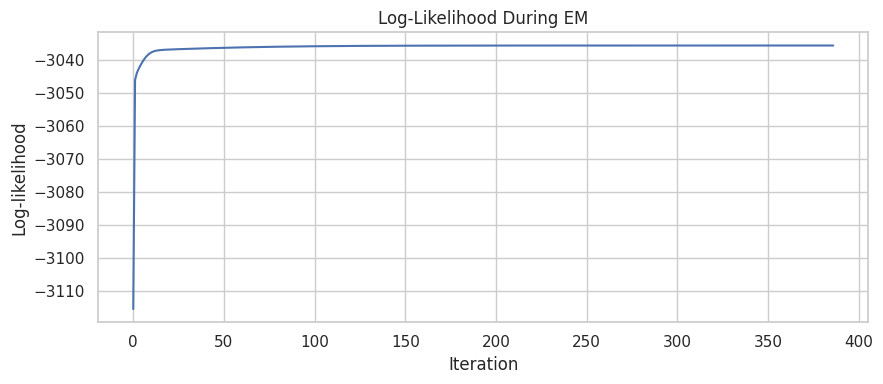

In [40]:
plt.figure(figsize=(9, 4))
sns.lineplot(data=table, x="Iteration", y="Log-likelihood ℓ")
plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")
plt.title("Log-Likelihood During EM")
plt.tight_layout()
plt.show()

### 7. Plot the Fitted Mixture Model

We visualize the final overlapping Gaussian components alongside the total mixture density curve relative to the empirical distribution histogram.

Component 1 (higher-mean; reported as Children): mean = 69.786 in, variance = 5.475 in², weight π₁ = 0.356
Component 2 (lower-mean; reported as Mothers):  mean = 64.299 in, variance = 5.793 in², weight π₂ = 0.644
Approximate equal-posterior boundary: 67.65 inches
Global mean: 66.25 inches


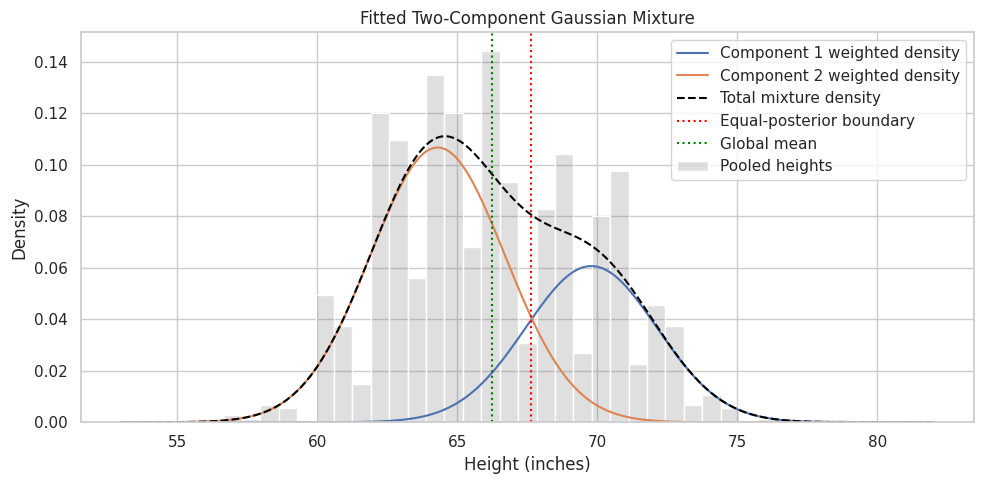

In [41]:
print(f"Component 1 (higher-mean; reported as Children): mean = {mu[0]:.3f} in, variance = {var[0]:.3f} in², weight π₁ = {pi[0]:.3f}")
print(f"Component 2 (lower-mean; reported as Mothers):  mean = {mu[1]:.3f} in, variance = {var[1]:.3f} in², weight π₂ = {pi[1]:.3f}")

grid = np.linspace(x.min() - 3, x.max() + 3, 500)
component_density = weighted_pdfs(grid, mu, var, pi)
mixture_density = component_density.sum(axis=1)
posterior_grid = e_step(grid, mu, var, pi)[:, 0]
boundary = grid[np.argmin(np.abs(posterior_grid - 0.5))]

print(f"Approximate equal-posterior boundary: {boundary:.2f} inches")
print(f"Global mean: {x.mean():.2f} inches")

# Seaborn draws the pooled-height distribution; component curves are the fitted densities.
plt.figure(figsize=(10, 5))
sns.histplot(x=x, bins=35, stat="density", color="gray", alpha=0.25, label="Pooled heights")
sns.lineplot(x=grid, y=component_density[:, 0], label="Component 1 weighted density")
sns.lineplot(x=grid, y=component_density[:, 1], label="Component 2 weighted density")
sns.lineplot(x=grid, y=mixture_density, label="Total mixture density", linestyle="--", color="black")
plt.axvline(boundary, color="red", linestyle=":", label="Equal-posterior boundary")
plt.axvline(x.mean(), color="green", linestyle=":", label="Global mean")
plt.xlabel("Height (inches)")
plt.ylabel("Density")
plt.title("Fitted Two-Component Gaussian Mixture")
plt.legend()
plt.tight_layout()
plt.show()

### 8. Evaluating a Global Mean Split vs. EM

#### Why a Hard Split at the Global Mean is Insufficient:

1. **Ignores Relative Variance:** It assumes symmetric, equal-variance subgroups, which is rarely true of real-world biological samples.
2. **Ignores Mixing Weights:** If one subgroup is significantly larger than the other, the optimal classification boundary shifts away from the global average.
3. **Forces Deterministic Assignments:** A hard threshold fails to capture uncertainty for measurements close to the boundary.

By contrast, **EM** soft-clusters observations by estimating the underlying probability densities, yielding mathematically consistent classification thresholds based on posterior probabilities.

### 9. Posterior Inference for a Test Height

Let's evaluate the model's classification confidence for a test height of **63 inches** using Bayes' Theorem:

$$P(\text{Component } k \mid h) = \frac{\pi_k \mathcal{N}(h \mid \mu_k, \sigma_k^2)}{p(h)}$$

In [42]:
TEST_HEIGHT = 63
UNIT = "in"

h = TEST_HEIGHT / 2.54 if UNIT.lower() == "cm" else TEST_HEIGHT

joint = weighted_pdfs(np.array([h]), mu, var, pi)[0]
evidence = joint.sum()
p_component1, p_component2 = joint / evidence

print(f"Test height: {TEST_HEIGHT} {UNIT} ({h:.2f} inches)")
print(f"Weighted density for component 1: {joint[0]:.8f}")
print(f"Weighted density for component 2: {joint[1]:.8f}")
print(f"Total density p(h):               {evidence:.8f}")
print()
print(f"P(Component 1 | h) = {p_component1:.6f} ({p_component1:.2%})")
print(f"P(Component 2 | h) = {p_component2:.6f} ({p_component2:.2%})")
print("Most probable component:", "Component 1 (reported as Children)" if p_component1 >= p_component2 else "Component 2 (reported as Mothers)")
print("Posterior probabilities sum to 1:", np.isclose(p_component1 + p_component2, 1.0))

Test height: 63 in (63.00 inches)
Weighted density for component 1: 0.00090537
Weighted density for component 2: 0.09227707
Total density p(h):               0.09318244

P(Component 1 | h) = 0.009716 (0.97%)
P(Component 2 | h) = 0.990284 (99.03%)
Most probable component: Component 2 (reported as Mothers)
Posterior probabilities sum to 1: True


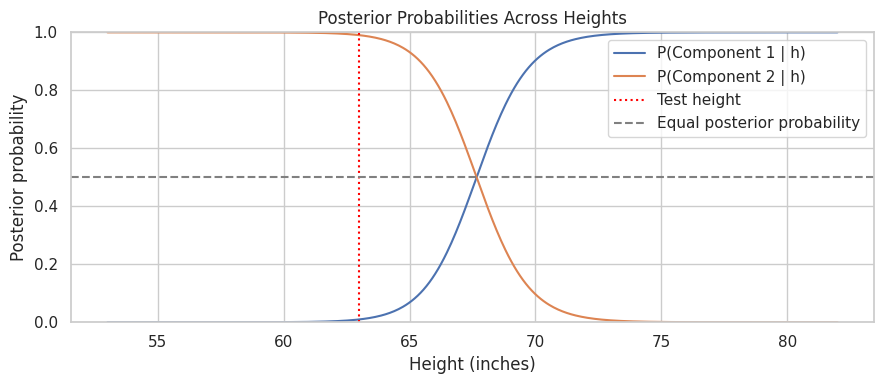

In [43]:
plt.figure(figsize=(9, 4))
sns.lineplot(x=grid, y=posterior_grid, label="P(Component 1 | h)")
sns.lineplot(x=grid, y=1 - posterior_grid, label="P(Component 2 | h)")
plt.axvline(h, color="red", linestyle=":", label="Test height")
plt.axhline(0.5, color="gray", linestyle="--", label="Equal posterior probability")
plt.xlabel("Height (inches)")
plt.ylabel("Posterior probability")
plt.title("Posterior Probabilities Across Heights")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

### 10. Part 1 Conclusion

- **Component 1 (Children):** Mean $\approx 69.79$ in, Variance $\approx 5.48$, Weight $\approx 35.6\%$
- **Component 2 (Mothers):** Mean $\approx 64.30$ in, Variance $\approx 5.79$, Weight $\approx 64.4\%$
- **Classification Performance:** A test height of $63$ inches yields a $99.03\%$ posterior probability of belonging to Component 2 (Mothers).

These probabilities are statistical properties of the model, not definite biological truths. Because the children's pool contains both males and females, the fitted components reflect overlapping subgroups rather than a clean split.

<a id='part-2'></a>
# Part 2: Bayesian Probability for Sentiment Analysis

We apply **Bayes' Theorem** to estimate the sentiment polarity of movie reviews based on specific keywords. Given a keyword $W$, we calculate the posterior probability that a review is positive:

$$P(\text{Positive} \mid W) = \frac{P(W \mid \text{Positive}) \times P(\text{Positive})}{P(W)}$$

In [44]:
POSITIVE_KEYWORDS = ("excellent", "amazing", "wonderful")
NEGATIVE_KEYWORDS = ("terrible", "awful", "worst")
KEYWORDS = POSITIVE_KEYWORDS + NEGATIVE_KEYWORDS

print("Keywords:", KEYWORDS)

Keywords: ('excellent', 'amazing', 'wonderful', 'terrible', 'awful', 'worst')


In [45]:
from google.colab import files

uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Please upload exactly one CSV file.")

filename, file_bytes = next(iter(uploaded.items()))

text_file = io.TextIOWrapper(
    io.BytesIO(file_bytes),
    encoding="utf-8-sig",
    newline=""
)

reader = csv.DictReader(text_file)

if reader.fieldnames is None:
    raise ValueError("The uploaded file is empty or has no header.")

# Match required column names case-insensitively and ignore surrounding spaces.
columns = {name.strip().casefold(): name for name in reader.fieldnames}
missing_columns = {"review", "sentiment"} - columns.keys()

if missing_columns:
    raise ValueError(
        "Missing required column(s): " + ", ".join(sorted(missing_columns))
    )

print(f"Uploaded: {filename}")
print("Columns found:", reader.fieldnames)

Saving IMDB Dataset.csv to IMDB Dataset (1).csv
Uploaded: IMDB Dataset (1).csv
Columns found: ['review', 'sentiment']


In [46]:
def analyze_reviews(csv_reader, column_names, keywords):
    patterns = {
        keyword: re.compile(r"\b" + re.escape(keyword.casefold()) + r"\b")
        for keyword in keywords
    }

    total_reviews = 0
    positive_reviews = 0
    keyword_review_counts = {keyword: 0 for keyword in keywords}
    positive_keyword_counts = {keyword: 0 for keyword in keywords}

    # CSV row numbering starts at 2 because row 1 contains the headers.
    for row_number, row in enumerate(csv_reader, start=2):
        review = row.get(column_names["review"]) or ""
        sentiment_value = row.get(column_names["sentiment"]) or ""
        sentiment = sentiment_value.strip().casefold()

        if sentiment not in {"positive", "negative"}:
            raise ValueError(
                f"Row {row_number} has unsupported sentiment "
                f"{sentiment_value!r}; expected 'positive' or 'negative'."
            )

        total_reviews += 1
        is_positive = sentiment == "positive"

        if is_positive:
            positive_reviews += 1

        review = review.casefold()

        for keyword, pattern in patterns.items():
            if pattern.search(review):
                keyword_review_counts[keyword] += 1
                if is_positive:
                    positive_keyword_counts[keyword] += 1

    if total_reviews == 0:
        raise ValueError("The CSV contains no review records.")

    if positive_reviews == 0:
        raise ValueError("The dataset contains no positive reviews.")

    prior_positive = positive_reviews / total_reviews
    results = []

    for keyword in keywords:
        keyword_count = keyword_review_counts[keyword]

        if keyword_count == 0:
            raise ValueError(
                f"The keyword {keyword!r} was not found, "
                "so its posterior cannot be calculated."
            )

        positive_keyword_count = positive_keyword_counts[keyword]

        likelihood = positive_keyword_count / positive_reviews
        marginal = keyword_count / total_reviews
        posterior = likelihood * prior_positive / marginal

        results.append({
            "Keyword": keyword,
            "Prior P(Positive)": prior_positive,
            "Likelihood P(keyword | Positive)": likelihood,
            "Marginal P(keyword)": marginal,
            "Posterior P(Positive | keyword)": posterior,
            "Positive matches": positive_keyword_count,
            "All keyword matches": keyword_count,
            "Total reviews": total_reviews,
        })

    return results


text_file = io.TextIOWrapper(io.BytesIO(file_bytes), encoding="utf-8-sig", newline="")
reader = csv.DictReader(text_file)
results = analyze_reviews(reader, columns, KEYWORDS)

print(f"Total reviews: {results[0]['Total reviews']:,}")
print(f"Positive reviews: {results[0]['Prior P(Positive)']:.2%} of the dataset")

Total reviews: 50,000
Positive reviews: 50.00% of the dataset


In [47]:
import pandas as pd

results_df = pd.DataFrame(results)

probability_columns = [
    "Prior P(Positive)",
    "Likelihood P(keyword | Positive)",
    "Marginal P(keyword)",
    "Posterior P(Positive | keyword)",
]

display(
    results_df.style.format({
        column: "{:.6f}" for column in probability_columns
    })
)

,Keyword,Prior P(Positive),Likelihood P(keyword | Positive),Marginal P(keyword),Posterior P(Positive | keyword),Positive matches,All keyword matches,Total reviews
0,excellent,0.500000,0.114720,0.071040,0.807432,2868,3552,50000
1,amazing,0.500000,0.067160,0.043160,0.778035,1679,2158,50000
2,wonderful,0.500000,0.090320,0.055600,0.812230,2258,2780,50000
3,terrible,0.500000,0.015320,0.054020,0.141799,383,2701,50000
4,awful,0.500000,0.011360,0.057660,0.098508,284,2883,50000
5,worst,0.500000,0.016440,0.088680,0.092693,411,4434,50000


In [48]:
example = results[0]

prior = example["Prior P(Positive)"]
likelihood = example["Likelihood P(keyword | Positive)"]
marginal = example["Marginal P(keyword)"]
posterior = example["Posterior P(Positive | keyword)"]

print(f"Example keyword: {example['Keyword']}")
print("Bayes' theorem:")
print("P(Positive | keyword) = P(keyword | Positive) × P(Positive) / P(keyword)")
print(
    f"                     = {likelihood:.6f} × {prior:.6f} / {marginal:.6f}"
)
print(f"                     = {posterior:.6f}")
print(f"                     = {posterior:.2%}")

# Cross-check: the posterior should equal the proportion of keyword-matching
# reviews labeled positive.
count_based_posterior = (
    example["Positive matches"] / example["All keyword matches"]
)
assert math.isclose(posterior, count_based_posterior, rel_tol=1e-9)

print("Count-based cross-check passed.")

Example keyword: excellent
Bayes' theorem:
P(Positive | keyword) = P(keyword | Positive) × P(Positive) / P(keyword)
                     = 0.114720 × 0.500000 / 0.071040
                     = 0.807432
                     = 80.74%
Count-based cross-check passed.


In [49]:

print(
    "Each posterior is the proportion of reviews containing that keyword "
    "that are labeled positive in this dataset. The keyword is counted once "
    "per review, even if it appears multiple times. These are dataset "
    "associations, not guaranteed predictions: this method does not account "
    "for negation, sarcasm, word order, or the full context of a review."
)

Each posterior is the proportion of reviews containing that keyword that are labeled positive in this dataset. The keyword is counted once per review, even if it appears multiple times. These are dataset associations, not guaranteed predictions: this method does not account for negation, sarcasm, word order, or the full context of a review.


<a id='part-4'></a>
# Part 4: Gradient Descent Implementation Using Python and SciPy

In this section, we implement a linear model optimization using Gradient Descent with independent biases for each observation, verifying our analytical gradients against numerical derivatives from `SciPy`.

*Note: All necessary libraries are imported in the consolidated imports cell at the top.*

In [51]:
#data and starting values
X = np.array([[1, 3],[4, 10]])

#target
y= np.array([[5],[6]])

#weights
m = np.array([[-1.0],[2.0]])

#bias (initialized as [[1.0], [1.0]], but will be updated independently)
b = np.array([[1.0],[1.0]])

n = X.shape[0]

learning_rate = 0.01
num_updates = 3

In [52]:
def derivative_function(equation,x0):
    f = np.vectorize(equation)
    return float(derivative(f, x0).df)

print(
      round(derivative_function(lambda x: x**2 + 3*x, 2.0), 6))

7.0


In [53]:
def cost(m,b):
     """MSE as a matrix expression: J = (1/n) * e^T e, with e = Xm + b - y."""
     e = X @ m + b - y
     return ((1/n) * (e.T @ e)).item()

In [54]:
def scipy_gradient(m_, b_):
    """Gradient of J obtained with SciPy, calculating independent derivatives for m and b."""
    dm1 = derivative_function(lambda v: cost(np.array([[v], [m_[1, 0]]]), b_), m_[0, 0])
    dm2 = derivative_function(lambda v: cost(np.array([[m_[0, 0]], [v]]), b_), m_[1, 0])
    # Calculate independent derivatives for each bias entry in the vector b
    db1 = derivative_function(lambda v: cost(m_, np.array([[v], [b_[1, 0]]])), b_[0, 0])
    db2 = derivative_function(lambda v: cost(m_, np.array([[b_[0, 0]], [v]])), b_[1, 0])
    return dm1, dm2, db1, db2

In [55]:
# Gradient descent, every step visible with independent biases

history_m1, history_m2, history_b1, history_b2, history_J = [], [], [], [], []

for step in range(num_updates+1):
    y_hat = X @ m + b

    error = y_hat - y

    J = ((error.T @ error)/n).item()

    history_m1.append(m[0, 0])
    history_m2.append(m[1, 0])
    history_b1.append(b[0, 0])
    history_b2.append(b[1, 0])
    history_J.append(J)

    print(f"\n--- Iteration {step} ---")
    print("m      =", m.ravel())
    print("b      =", b.ravel())
    print("y_hat  =", y_hat.ravel())
    print("error  =", error.ravel())
    print("MSE J  =", J)

    if step == num_updates:
        break

    # gradients (matrix form for independent parameters)
    grad_m = (2 / n) * (X.T @ error)
    grad_b = (2 / n) * error

    print("dJ/dm  =", grad_m.ravel())
    print("dJ/db  =", grad_b.ravel())

    # check against SciPy's numerical derivative
    sm1, sm2, sb1, sb2 = scipy_gradient(m, b)
    print("SciPy check (dm1, dm2, db1, db2) =", round(sm1, 4), round(sm2, 4), round(sb1, 4), round(sb2, 4))

    # Step D: update
    m = m - learning_rate * grad_m
    b = b - learning_rate * grad_b


--- Iteration 0 ---
m      = [-1.  2.]
b      = [1. 1.]
y_hat  = [ 6. 17.]
error  = [ 1. 11.]
MSE J  = 61.0
dJ/dm  = [ 45. 113.]
dJ/db  = [ 1. 11.]
SciPy check (dm1, dm2, db1, db2) = 45.0 113.0 1.0 11.0

--- Iteration 1 ---
m      = [-1.45  0.87]
b      = [0.99 0.89]
y_hat  = [2.15 3.79]
error  = [-2.85 -2.21]
MSE J  = 6.503300000000002
dJ/dm  = [-11.69 -30.65]
dJ/db  = [-2.85 -2.21]
SciPy check (dm1, dm2, db1, db2) = -11.69 -30.65 -2.85 -2.21

--- Iteration 2 ---
m      = [-1.3331  1.1765]
b      = [1.0185 0.9121]
y_hat  = [3.2149 7.3447]
error  = [-1.7851  1.3447]
MSE J  = 2.4974000499999987
dJ/dm  = [3.5937 8.0917]
dJ/db  = [-1.7851  1.3447]
SciPy check (dm1, dm2, db1, db2) = 3.5937 8.0917 -1.7851 1.3447

--- Iteration 3 ---
m      = [-1.369037  1.095583]
b      = [1.036351 0.898653]
y_hat  = [2.954063 6.378335]
error  = [-2.045937  0.378335]
MSE J  = 2.1644977900969997


In [56]:
final_pred = X @ m + b
print("\nFinal m =", m.ravel())
print("Final b =", b.ravel())
print("Final predictions =", final_pred.ravel(), " actual y =", y.ravel())


Final m = [-1.369037  1.095583]
Final b = [1.036351 0.898653]
Final predictions = [2.954063 6.378335]  actual y = [5 6]


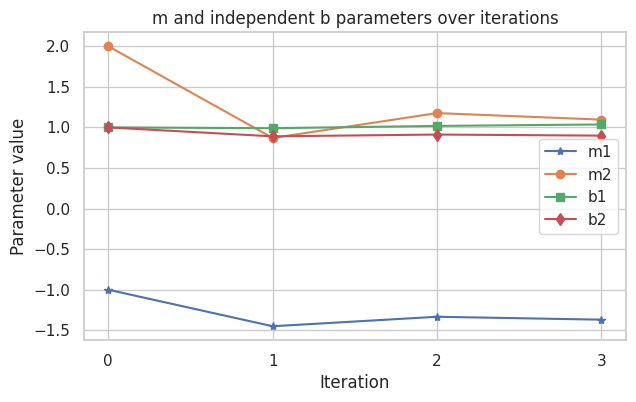

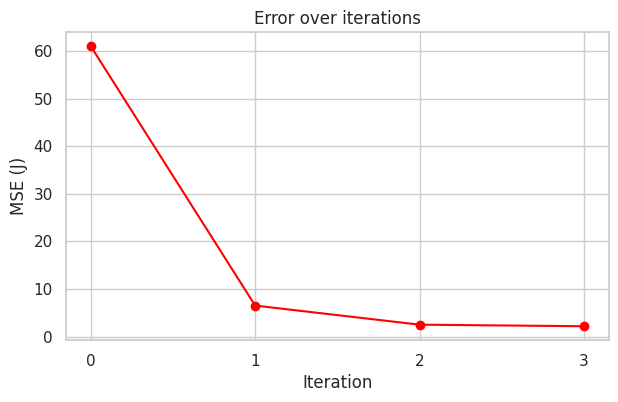

In [57]:
#plots showing independent biases
iters = list(range(num_updates + 1))

plt.figure(figsize=(7, 4))
plt.plot(iters, history_m1, marker="*", label="m1")
plt.plot(iters, history_m2, marker="o", label="m2")
plt.plot(iters, history_b1, marker="s", label="b1")
plt.plot(iters, history_b2, marker="d", label="b2")
plt.xlabel("Iteration")
plt.ylabel("Parameter value")
plt.title("m and independent b parameters over iterations")
plt.xticks(iters)
plt.legend()
plt.grid(True)

plt.figure(figsize=(7, 4))
plt.plot(iters, history_J, marker="o", color="red")
plt.xlabel("Iteration")
plt.ylabel("MSE (J)")
plt.title("Error over iterations")
plt.xticks(iters)
plt.grid(True)

plt.show()